# Aula ML 02 — Regressão linear e MLflow

Consumo de cerveja em São Paulo, 2015. Slides em `index.html`.

| slide | célula |
|---|---|
| 1 | O arquivo |
| 4 | Pré-processamento |
| 5 | Correlação com o consumo |
| 6 | Temperatura máxima |
| 7 | Fim de semana |
| 9 | O erro |
| 10 | Média |
| 11 | MAE |
| 12 | RMSE |
| 14 | Primeiro treino |
| 15 | Segundo treino |
| 16 | MLflow |


## De onde veio o arquivo

[Beer Consumption - Sao Paulo](https://www.kaggle.com/datasets/dongeorge/beer-consumption-sao-paulo), publicado por dongeorge.
A aula lê `dados/Consumo_cerveja.csv`.


In [1]:
import kagglehub
kagglehub.dataset_download("dongeorge/beer-consumption-sao-paulo")


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


'/Users/teixeirah/.cache/kagglehub/datasets/dongeorge/beer-consumption-sao-paulo/versions/2'

## ▸ Slide 1 · O arquivo

In [2]:
import os
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")

import numpy as np
import pandas as pd
import mlflow
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

mlflow.set_tracking_uri("mlruns")
mlflow.set_experiment("aula-ml-2-cerveja")

bruto = pd.read_csv("dados/Consumo_cerveja.csv")
bruto.head(3)


2026/10/06 23:52:07 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/10/06 23:52:08 INFO mlflow.tracking.fluent: Experiment with name 'aula-ml-2-cerveja' does not exist. Creating a new experiment.


,Data,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
0,2015-01-01,"27,3","23,9","32,5",0,0,25.461
1,2015-01-02,"27,02","24,5","33,5",0,0,28.972
2,2015-01-03,"24,82","22,4","29,9",0,1,30.814


## ▸ Slide 4 · Pré-processamento

In [3]:
print("linhas no arquivo", len(bruto))
print("linhas vazias", int(bruto.isna().all(axis=1).sum()))

dias = bruto.dropna(how="all").copy()
for coluna in [
    "Temperatura Media (C)",
    "Temperatura Minima (C)",
    "Temperatura Maxima (C)",
    "Precipitacao (mm)",
]:
    dias[coluna] = dias[coluna].astype(str).str.replace(",", ".", regex=False).astype(float)

alvo = "Consumo de cerveja (litros)"
dias[alvo] = dias[alvo].astype(float)
print("dias", len(dias))
dias.head(3)


linhas no arquivo 365
linhas vazias 0
dias 365


,Data,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
0,2015-01-01,27.30,23.9,32.5,0.0,0,25.461
1,2015-01-02,27.02,24.5,33.5,0.0,0,28.972
2,2015-01-03,24.82,22.4,29.9,0.0,1,30.814


## ▸ Slide 5 · Correlação com o consumo

Temperatura Media (C)     0.575
Temperatura Minima (C)    0.393
Temperatura Maxima (C)    0.643
Precipitacao (mm)        -0.194
Final de Semana           0.506
Name: Consumo de cerveja (litros), dtype: float64


<Axes: >

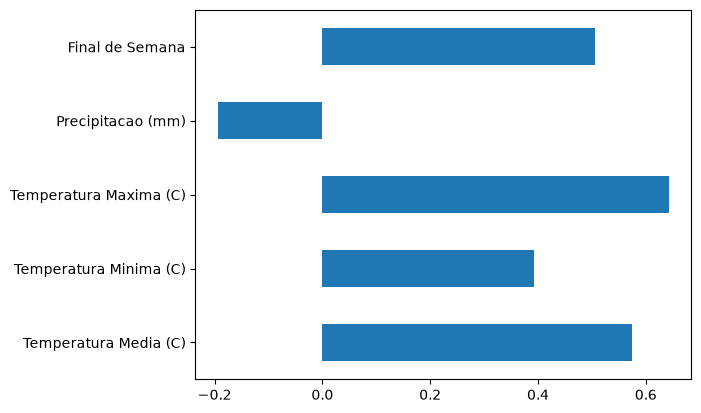

In [4]:
colunas = [
    "Temperatura Media (C)",
    "Temperatura Minima (C)",
    "Temperatura Maxima (C)",
    "Precipitacao (mm)",
    "Final de Semana",
]
correlacao = dias[colunas + [alvo]].corr()[alvo].drop(alvo)
print(correlacao.round(3))
correlacao.plot.barh()


## ▸ Slide 6 · Temperatura máxima

<Axes: xlabel='Temperatura Maxima (C)', ylabel='Consumo de cerveja (litros)'>

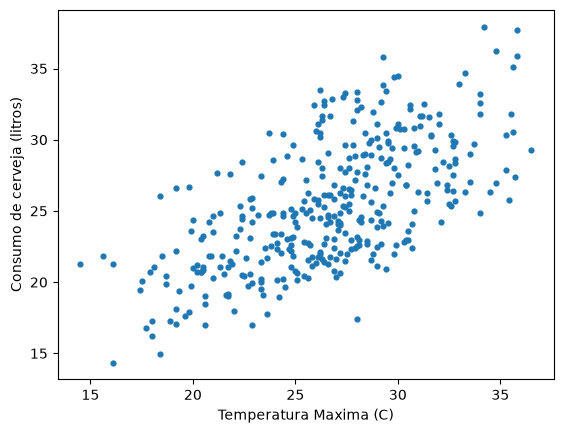

In [5]:
dias.plot.scatter(x="Temperatura Maxima (C)", y=alvo, s=12)


## ▸ Slide 7 · Fim de semana

Final de Semana
0    24.00
1    28.92
Name: Consumo de cerveja (litros), dtype: float64


<Axes: xlabel='Final de Semana'>

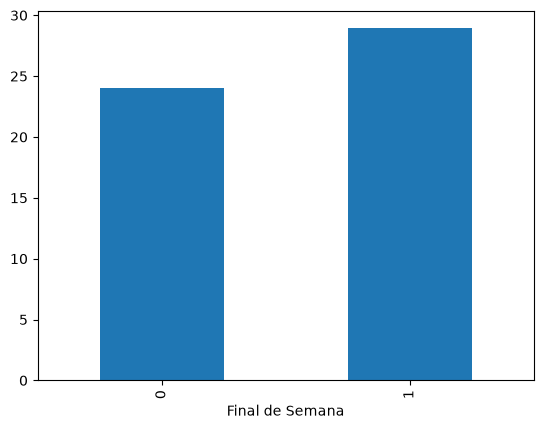

In [6]:
print(dias.groupby("Final de Semana")[alvo].mean().round(2))
dias.groupby("Final de Semana")[alvo].mean().plot.bar()


## ▸ Slide 8 · Regressão linear

Consumo do dia, em litros:

`b0 + b1 × temperatura máxima + b2 × precipitação + b3 × fim de semana`

b0 é um valor fixo. b1 é litros a mais por °C. b2 é litros a mais por mm de chuva. b3 é litros a mais se o dia é fim de semana. Treinar é calcular esses quatro números com os dias de 2015.


## ▸ Slide 9 · O erro

In [7]:
previsto = np.array([30, 22])
real = np.array([25, 30])
erro = previsto - real
print("erro", erro)


erro [ 5 -8]


## ▸ Slide 10 · Média

25% dos dias ficam de fora do cálculo. MAE e RMSE abaixo são desses dias.


In [8]:
print("média dos 365 dias", round(dias[alvo].mean(), 2))

entradas = ["Temperatura Maxima (C)", "Precipitacao (mm)", "Final de Semana"]
X = dias[entradas]
y = dias[alvo]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)

def metricas(y_verdadeiro, y_previsto):
    return {
        "mae": float(mean_absolute_error(y_verdadeiro, y_previsto)),
        "rmse": float(np.sqrt(mean_squared_error(y_verdadeiro, y_previsto))),
    }

prev_media = np.full(len(y_teste), fill_value=y_treino.mean())
m_media = metricas(y_teste, prev_media)
print("média no teste", {k: round(v, 3) for k, v in m_media.items()})
with mlflow.start_run(run_name="media"):
    mlflow.log_metrics({f"teste_{k}": v for k, v in m_media.items()})


média dos 365 dias 25.4
média no teste {'mae': 3.469, 'rmse': 4.198}


## ▸ Slide 11 · MAE

In [9]:
print("exemplo", round(np.abs(erro).mean(), 1))
print("média no teste", round(m_media["mae"], 3))


exemplo 6.5
média no teste 3.469


## ▸ Slide 12 · RMSE

In [10]:
print("exemplo", round(np.sqrt((erro ** 2).mean()), 3))
print("média no teste", round(m_media["rmse"], 3))


exemplo 6.671
média no teste 4.198


## ▸ Slide 13 · Coeficiente e erro

MAE e RMSE medem o erro da previsão, em litros. O coeficiente mede o efeito da coluna. Um coeficiente alto não significa erro baixo. Os dois números saem nos treinos abaixo.


## ▸ Slide 14 · Primeiro treino

In [11]:
so_temp = LinearRegression().fit(X_treino[["Temperatura Maxima (C)"]], y_treino)
print(f"b0 {so_temp.intercept_:.3f}  valor fixo, em litros")
print(f"b1 {so_temp.coef_[0]:.3f}  litros por °C")
m_temp = metricas(y_teste, so_temp.predict(X_teste[["Temperatura Maxima (C)"]]))
print({k: round(v, 3) for k, v in m_temp.items()})
with mlflow.start_run(run_name="temperatura"):
    mlflow.log_metrics({f"teste_{k}": v for k, v in m_temp.items()})


b0 7.715  valor fixo, em litros
b1 0.660  litros por °C
{'mae': 2.838, 'rmse': 3.518}


## ▸ Slide 15 · Segundo treino

In [12]:
completa = LinearRegression().fit(X_treino, y_treino)
print(f"b0 {completa.intercept_:.3f}  valor fixo, em litros")
print(f"b1 {completa.coef_[0]:.3f}  litros por °C")
print(f"b2 {completa.coef_[1]:.3f}  litros por mm de chuva")
print(f"b3 {completa.coef_[2]:.3f}  litros a mais no fim de semana")
m_completa = metricas(y_teste, completa.predict(X_teste))
print("média      ", {k: round(v, 3) for k, v in m_media.items()})
print("temperatura", {k: round(v, 3) for k, v in m_temp.items()})
print("completa   ", {k: round(v, 3) for k, v in m_completa.items()})
with mlflow.start_run(run_name="completa"):
    mlflow.log_metrics({f"teste_{k}": v for k, v in m_completa.items()})
    mlflow.sklearn.log_model(completa, name="modelo")


b0 6.628  valor fixo, em litros
b1 0.659  litros por °C
b2 -0.060  litros por mm de chuva
b3 5.159  litros a mais no fim de semana
média       {'mae': 3.469, 'rmse': 4.198}
temperatura {'mae': 2.838, 'rmse': 3.518}
completa    {'mae': 2.063, 'rmse': 2.397}


2026/10/06 23:52:11 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


## ▸ Slide 16 · MLflow

`MLFLOW_ALLOW_FILE_STORE=true mlflow ui --backend-store-uri mlruns`


In [13]:
runs = mlflow.search_runs(experiment_names=["aula-ml-2-cerveja"], order_by=["metrics.teste_rmse ASC"])
print(runs[["tags.mlflow.runName", "metrics.teste_mae", "metrics.teste_rmse"]].round(3).to_string(index=False))


tags.mlflow.runName  metrics.teste_mae  metrics.teste_rmse
           completa              2.063               2.397
        temperatura              2.838               3.518
              media              3.469               4.198
